# Feature analysis: GTZAN genre classification


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.feature_selection import f_classif
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

ROOT = Path.cwd()
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "scripts")]
from analysis import feature_family, group_permutation_importance
from baseline import GROUPS, load

FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

SURFACE, INK, INK2, GRID, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#cfcec8"
GROUP_COLOR = {"timbre": "#2a78d6", "harmony": "#eb6834", "rhythm": "#1baf7a"}
HIGHLIGHT = "#2a78d6"
DIVERGING = LinearSegmentedColormap.from_list("bgr", ["#1c5cab", "#f0efec", "#c23b3a"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2,
    "ytick.color": INK2, "text.color": INK, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titlesize": 10, "axes.titleweight": "bold",
    "figure.dpi": 110,
})

Xtr, ytr, names, genres = load("train")
Xva, yva, _, _ = load("valid")
names, genres = [str(n) for n in names], [str(g) for g in genres]


def group_of(name):
    fam = feature_family(name)
    return next(g for g, fams in GROUPS.items() if fam in fams)


def legend_groups(ax, loc="lower right"):
    ax.legend(handles=[Patch(color=c, label=g) for g, c in GROUP_COLOR.items()],
              frameon=False, loc=loc)


def save(fig, name):
    fig.savefig(FIG / name, dpi=160, bbox_inches="tight")


print(f"train {Xtr.shape}, valid {Xva.shape}, {len(genres)} genres")

train (442, 145), valid (197, 145), 10 genres


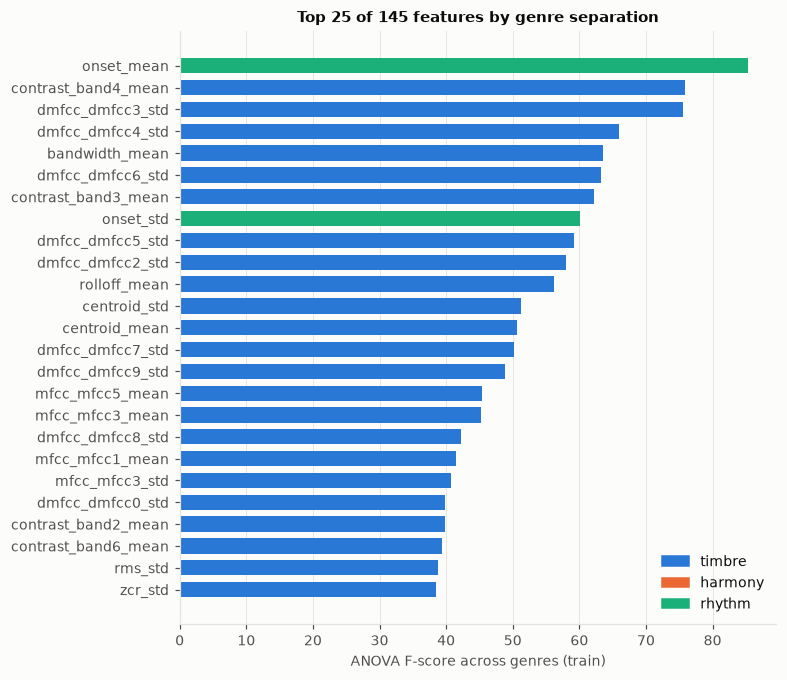

,mean F
timbre,23.7
harmony,12.2
rhythm,50.0


In [2]:
F, _ = f_classif(Xtr, ytr)
F = np.nan_to_num(F)
top = 25
order = np.argsort(F)[::-1][:top][::-1]

fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(range(top), F[order], height=0.7,
        color=[GROUP_COLOR[group_of(names[i])] for i in order])
ax.set_yticks(range(top), [names[i] for i in order])
ax.set_xlabel("ANOVA F-score across genres (train)")
ax.set_title(f"Top {top} of {len(names)} features by genre separation")
ax.grid(axis="y", visible=False)
legend_groups(ax)
save(fig, "1_discriminability.png")
plt.show()

pd.Series({g: F[[i for i, n in enumerate(names) if group_of(n) == g]].mean() for g in GROUPS},
          name="mean F").round(1).to_frame()

**Findings**
- 23 of the top 25 features are timbre. Most of them describe how the spectrum **changes** (ΔMFCC std, contrast) rather than its average shape.
- The single best feature is `onset_mean` (rhythm, F ≈ 85). Rhythm has the highest mean F of the three groups, but it has only 3 features, so that mean doesn't make it the most useful group.
- No harmony feature makes the top 25.

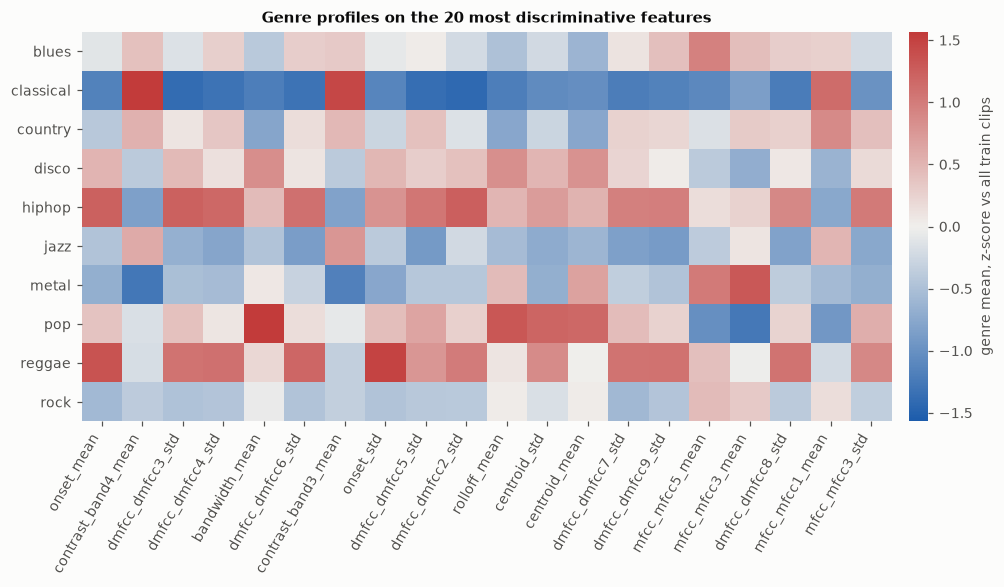

,largest |z|
rock,0.59
disco,0.84
country,0.87
jazz,0.90
blues,0.95
hiphop,1.25
metal,1.30
reggae,1.49
pop,1.56
classical,1.57


In [3]:
cols = np.argsort(F)[::-1][:20]
Z = (Xtr[:, cols] - Xtr[:, cols].mean(0)) / Xtr[:, cols].std(0)
M = np.array([Z[ytr == g].mean(0) for g in range(len(genres))])
lim = np.abs(M).max()

fig, ax = plt.subplots(figsize=(10, 4.6))
im = ax.imshow(M, cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(cols)), [names[i] for i in cols], rotation=60, ha="right")
ax.set_yticks(range(len(genres)), genres)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cb.set_label("genre mean, z-score vs all train clips")
cb.outline.set_visible(False)
ax.set_title("Genre profiles on the 20 most discriminative features")
save(fig, "2_genre_profiles.png")
plt.show()

profile = pd.DataFrame(M, index=genres, columns=[names[i] for i in cols])
profile.abs().max(axis=1).round(2).sort_values().rename("largest |z|").to_frame()

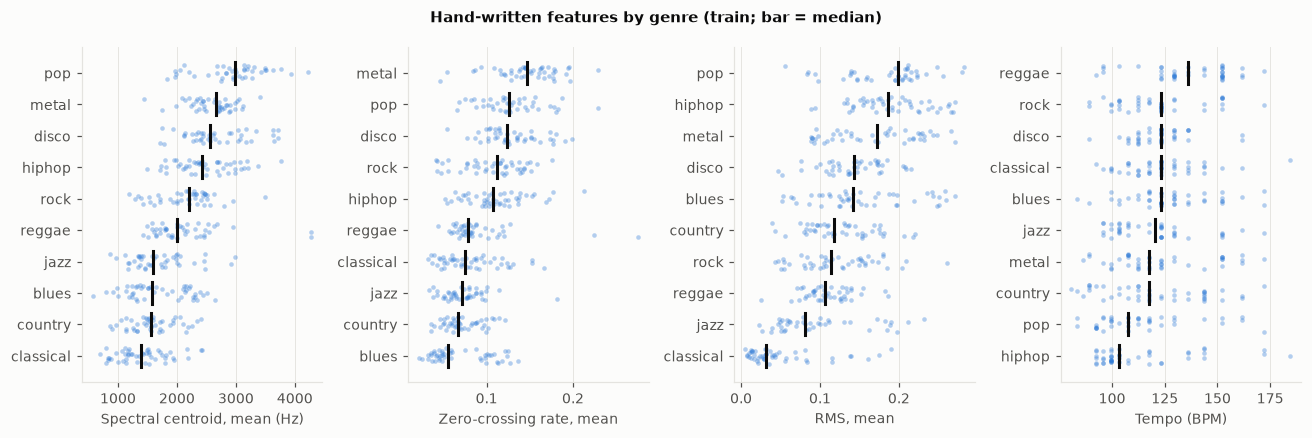

,"Spectral centroid, mean (Hz)","Zero-crossing rate, mean","RMS, mean",Tempo (BPM)
blues,1574.983032,0.055,0.141,123.046997
classical,1385.873047,0.075,0.032,123.046997
country,1555.875977,0.067,0.118,117.454002
disco,2565.322998,0.124,0.143,123.046997
hiphop,2433.709961,0.107,0.186,103.359001
jazz,1598.385010,0.072,0.081,120.250000
metal,2664.077881,0.147,0.172,117.454002
pop,2988.746094,0.126,0.198,107.666000
reggae,2007.327026,0.079,0.106,135.998993
rock,2209.406982,0.112,0.113,123.046997


In [4]:
feats = [("centroid_mean", "Spectral centroid, mean (Hz)"),
         ("zcr_mean", "Zero-crossing rate, mean"),
         ("rms_mean", "RMS, mean"),
         ("tempo_bpm", "Tempo (BPM)")]
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 4, figsize=(12, 4))
for ax, (feat, label) in zip(axes, feats):
    v = Xtr[:, names.index(feat)]
    med = np.array([np.median(v[ytr == g]) for g in range(len(genres))])
    for row, g in enumerate(np.argsort(med)):
        vals = v[ytr == g]
        ax.scatter(vals, row + rng.uniform(-0.25, 0.25, len(vals)), s=9,
                   color=HIGHLIGHT, alpha=0.35, linewidths=0)
        ax.plot([med[g]] * 2, [row - 0.35, row + 0.35], color=INK, lw=2)
    ax.set_yticks(range(len(genres)), [genres[g] for g in np.argsort(med)])
    ax.set_xlabel(label)
    ax.grid(axis="y", visible=False)
fig.suptitle("Hand-written features by genre (train; bar = median)", fontweight="bold", fontsize=10)
fig.tight_layout()
save(fig, "3_own_features.png")
plt.show()

pd.DataFrame({label: [np.median(Xtr[ytr == g, names.index(f)]) for g in range(len(genres))]
              for f, label in feats}, index=genres).round(3)

valid accuracy: 0.635


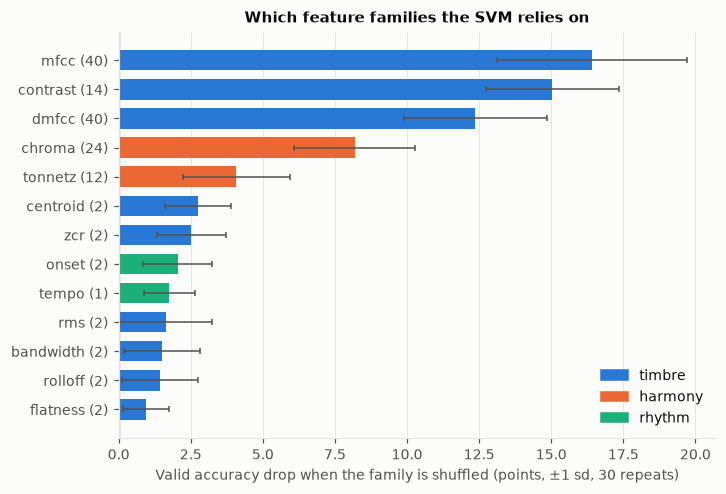

,dims,drop (pts),sd
mfcc,40,16.4,3.3
contrast,14,15.0,2.3
dmfcc,40,12.4,2.5
chroma,24,8.2,2.1
tonnetz,12,4.1,1.9
centroid,2,2.8,1.1
zcr,2,2.5,1.2
onset,2,2.0,1.2
tempo,1,1.8,0.9
rms,2,1.6,1.6


In [5]:
model = make_pipeline(StandardScaler(), SVC(C=10, gamma=0.001)).fit(Xtr, ytr)
print(f"valid accuracy: {model.score(Xva, yva):.3f}")
fams = {}
for i, n in enumerate(names):
    fams.setdefault(feature_family(n), []).append(i)
imp = group_permutation_importance(model, Xva, yva, fams, n_repeats=30)
order = sorted(imp, key=lambda k: imp[k][0])

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.barh(range(len(order)), [imp[k][0] * 100 for k in order],
        xerr=[imp[k][1] * 100 for k in order], height=0.7,
        color=[GROUP_COLOR[group_of(names[fams[k][0]])] for k in order],
        error_kw={"ecolor": INK2, "lw": 1, "capsize": 2})
ax.set_yticks(range(len(order)), [f"{k} ({len(fams[k])})" for k in order])
ax.axvline(0, color=INK2, lw=0.8)
ax.set_xlabel("Valid accuracy drop when the family is shuffled (points, ±1 sd, 30 repeats)")
ax.set_title("Which feature families the SVM relies on")
ax.grid(axis="y", visible=False)
legend_groups(ax)
save(fig, "4_family_importance.png")
plt.show()

pd.DataFrame({"dims": {k: len(v) for k, v in fams.items()},
              "drop (pts)": {k: 100 * m for k, (m, s) in imp.items()},
              "sd": {k: 100 * s for k, (m, s) in imp.items()}}
             ).sort_values("drop (pts)", ascending=False).round(1)

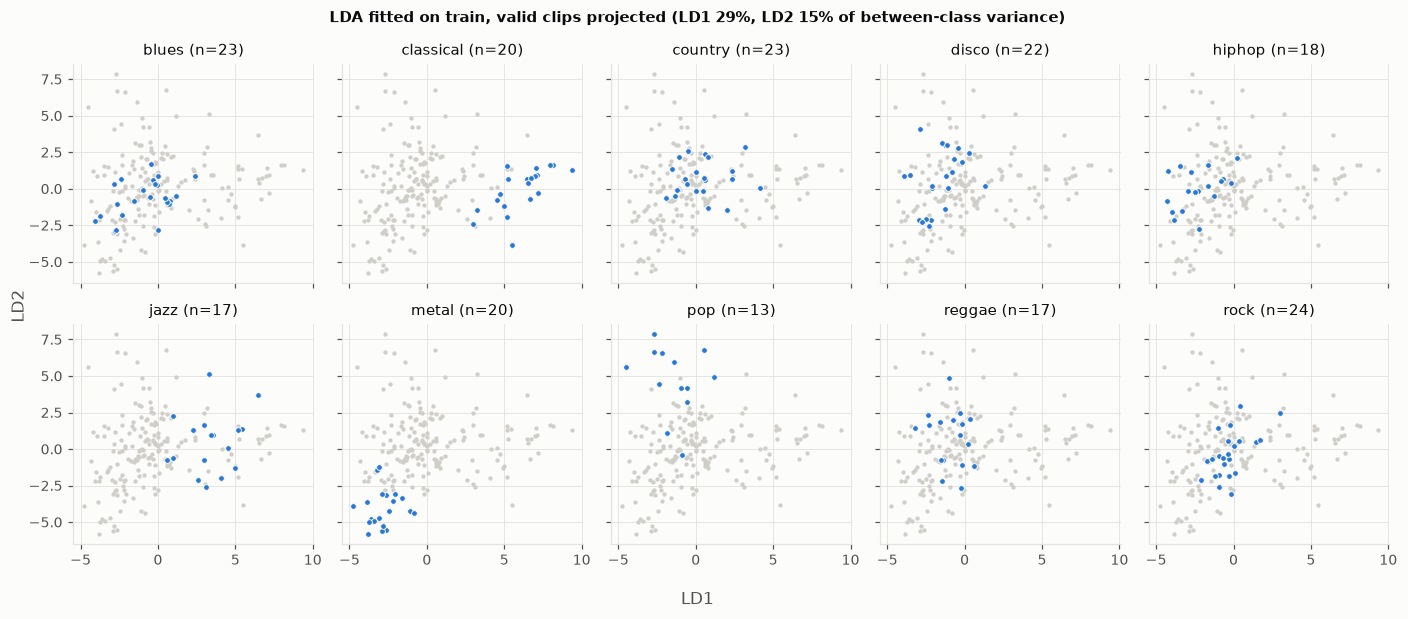

In [6]:
sc = StandardScaler().fit(Xtr)
lda = LinearDiscriminantAnalysis(n_components=2).fit(sc.transform(Xtr), ytr)
P = lda.transform(sc.transform(Xva))

fig, axes = plt.subplots(2, 5, figsize=(13, 5.6), sharex=True, sharey=True)
for g, ax in enumerate(axes.flat):
    ax.scatter(P[yva != g, 0], P[yva != g, 1], s=8, color=MUTED, linewidths=0)
    ax.scatter(P[yva == g, 0], P[yva == g, 1], s=14, color=HIGHLIGHT,
               edgecolors=SURFACE, linewidths=0.6)
    ax.set_title(f"{genres[g]} (n={int((yva == g).sum())})", fontweight="normal")
evr = lda.explained_variance_ratio_
fig.suptitle(f"LDA fitted on train, valid clips projected (LD1 {evr[0]:.0%}, LD2 {evr[1]:.0%} "
             "of between-class variance)", fontweight="bold", fontsize=10)
fig.supxlabel("LD1", color=INK2)
fig.supylabel("LD2", color=INK2)
fig.tight_layout()
save(fig, "5_lda_valid.png")
plt.show()

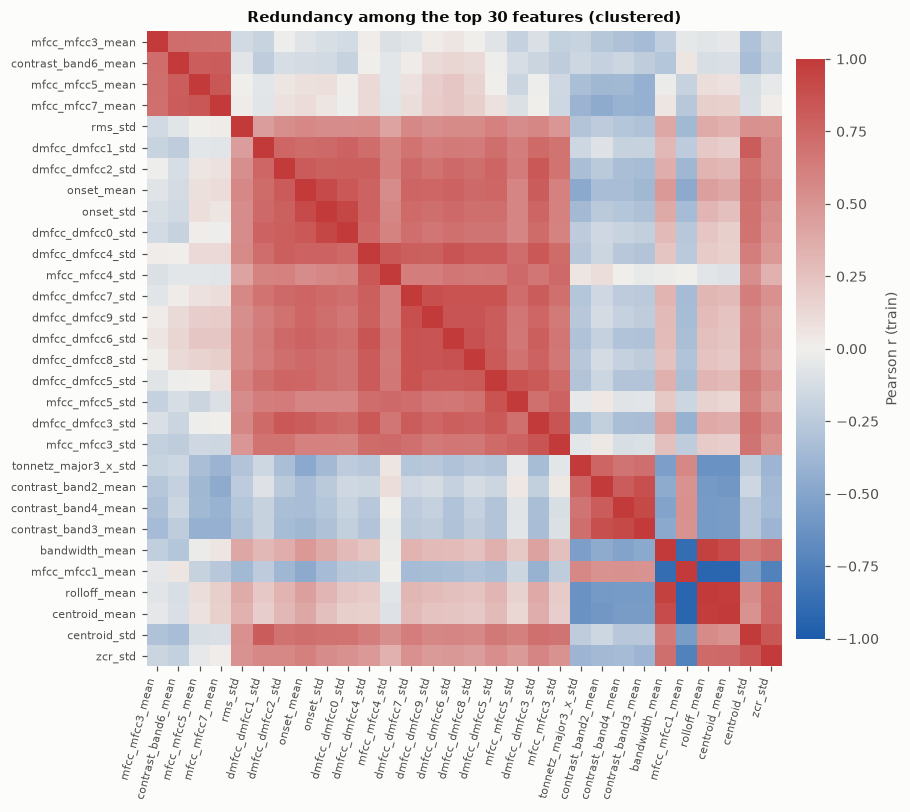

9 of 10440 feature pairs have |r| > 0.9


,feature A,feature B,r
0,centroid_mean,rolloff_mean,0.978
1,bandwidth_mean,rolloff_mean,0.954
2,dmfcc_dmfcc0_std,onset_std,0.934
3,mfcc_mfcc1_mean,centroid_mean,-0.930
4,mfcc_mfcc1_mean,rolloff_mean,-0.924
5,contrast_band3_mean,contrast_band4_mean,0.918
6,onset_mean,onset_std,0.910
7,tonnetz_minor3_x_std,tonnetz_major3_y_std,0.906
8,flatness_mean,flatness_std,0.903


In [7]:
R_all = np.corrcoef(Xtr, rowvar=False)
iu = np.triu_indices_from(R_all, 1)
pairs = sorted(((abs(R_all[i, j]), R_all[i, j], names[i], names[j]) for i, j in zip(*iu)
                if abs(R_all[i, j]) > 0.9), reverse=True)

top = 30
cols = np.argsort(F)[::-1][:top]
R = R_all[np.ix_(cols, cols)]
D = np.clip(1 - np.abs(R), 0, None)
np.fill_diagonal(D, 0)
leaf = leaves_list(linkage(squareform(D, checks=False), "average"))
cols, R = cols[leaf], R[np.ix_(leaf, leaf)]

fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(R, cmap=DIVERGING, vmin=-1, vmax=1)
labels = [names[i] for i in cols]
ax.set_xticks(range(top), labels, rotation=75, ha="right", fontsize=7)
ax.set_yticks(range(top), labels, fontsize=7)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cb.set_label("Pearson r (train)")
cb.outline.set_visible(False)
ax.set_title(f"Redundancy among the top {top} features (clustered)")
save(fig, "6_redundancy.png")
plt.show()

print(f"{len(pairs)} of {len(iu[0])} feature pairs have |r| > 0.9")
pd.DataFrame([(a, b, r) for _, r, a, b in pairs], columns=["feature A", "feature B", "r"]).round(3)

## Summary: what the features tell us

**Genre is mostly timbre, and especially how timbre changes.** The features that separate genres best are not the average sound of a clip but how much it varies over time: ΔMFCC spread, spectral contrast and onset strength. The SVM leans on MFCC, contrast and ΔMFCC more than on anything else.

**Harmony is weak on its own but not useless.** No chroma or tonnetz feature is in the top 25 by F-score. Even so, shuffling chroma costs the SVM about 8 points of valid accuracy, so it carries information that timbre lacks. On valid, adding harmony to timbre helped (0.574 → 0.614), but that gain didn't carry over to test (0.610 → 0.600), so the effect is real but small and noisy at this data size.

**Rhythm and the hand-written features are informative but redundant.** Onset strength is the best single feature, and centroid, ZCR and RMS all order the genres sensibly (dark classical to bright pop, quiet classical to loud pop and hip-hop). Each costs under 3 points when shuffled, though, because the MFCCs and ΔMFCCs already contain the same brightness, loudness and activity information. Tempo barely separates genres at all.

**The features overlap in three blocks:** activity (ΔMFCC std, onset, RMS std), brightness (centroid, rolloff, bandwidth, MFCC1) and spectral contrast. Only 9 of 10,440 feature pairs are near-duplicates (|r| > 0.9), so they overlap without repeating each other exactly.

**Some genres are easy and some are not separable with these features.** Classical, metal and pop each have a clear signature. Rock is close to average on every feature, which is why it is the hardest genre; blues, country and reggae also overlap with it in the middle of feature space.

**For the next models:** a CNN on log-mel spectrograms targets exactly the signal that matters (spectral change over time). A Tonnetz GNN on chroma alone will be limited, but because chroma adds information timbre lacks, combining it with timbre input is the version worth testing.